C:\Users\Madaan INFOTECH\AppData\Local\Temp\ipykernel_11732\1099492186.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


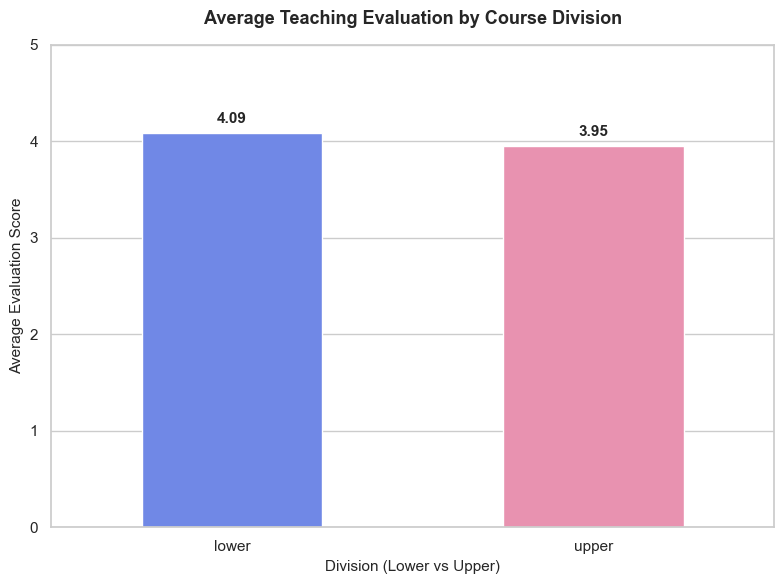

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Data setup
division_data = pd.DataFrame(
    {"Division": ["lower", "upper"], "Average Evaluation Score": [4.09, 3.95]}
)

# Figure setup
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Create bar plot
ax = sns.barplot(
    data=division_data,
    x="Division",
    y="Average Evaluation Score",
    palette=["#5c7cfa", "#f783ac"],
    width=0.5,
)

# Formatting
plt.title(
    "Average Teaching Evaluation by Course Division",
    fontsize=13,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Division (Lower vs Upper)", fontsize=11)
plt.ylabel("Average Evaluation Score", fontsize=11)
plt.ylim(0, 5)

# Adding value labels on top of bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.2f}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()


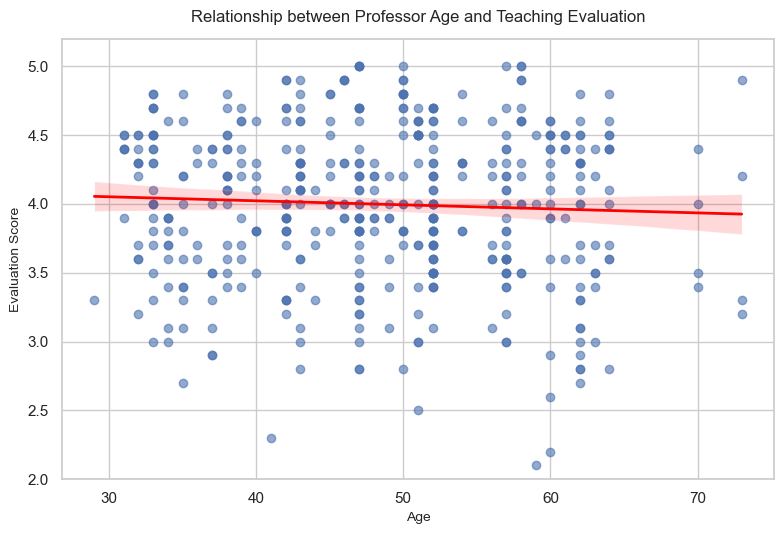

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# 1. Load the dataset into memory (defines 'df')
df = sm.datasets.get_rdataset("TeachingRatings", "AER").data

# Clean column names to lowercase
df.columns = [col.lower() for col in df.columns]

# 2. Set visual style
sns.set_theme(style="whitegrid")

# 3. Create figure and scatter plot with linear trendline
plt.figure(figsize=(8, 5.5))

sns.regplot(
    data=df,
    x="age",
    y="eval",
    scatter_kws={"alpha": 0.6, "color": "#4c72b0"},
    line_kws={"color": "red", "linewidth": 2},
)

plt.title(
    "Relationship between Professor Age and Teaching Evaluation",
    fontsize=12,
    pad=12,
)
plt.xlabel("Age", fontsize=10)
plt.ylabel("Evaluation Score", fontsize=10)
plt.ylim(2.0, 5.2)

plt.tight_layout()
plt.show()

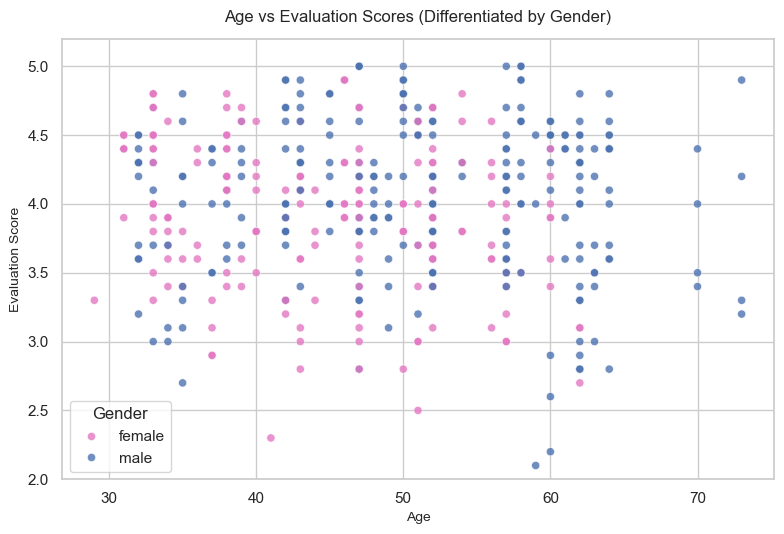

In [6]:
plt.figure(figsize=(8, 5.5))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=df,
    x="age",
    y="eval",
    hue="gender",
    palette={"female": "#e377c2", "male": "#4c72b0"},
    alpha=0.8,
    s=35,
)

plt.title("Age vs Evaluation Scores (Differentiated by Gender)", fontsize=12, pad=12)
plt.xlabel("Age", fontsize=10)
plt.ylabel("Evaluation Score", fontsize=10)
plt.ylim(2.0, 5.2)
plt.legend(title="Gender", loc="lower left")

plt.tight_layout()
plt.show()

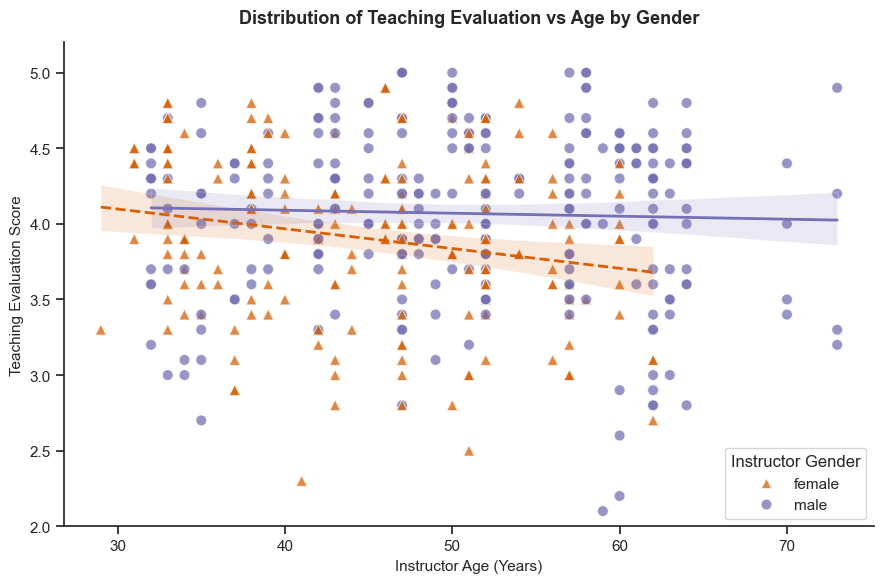

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# 1. Load dataset (defines 'df')
df = sm.datasets.get_rdataset("TeachingRatings", "AER").data
df.columns = [col.lower() for col in df.columns]

# 2. Custom visual styling
sns.set_style("ticks")
plt.figure(figsize=(9, 6))

# 3. Plot using lmplot-style formatting with custom palette and distinct regression lines
ax = sns.scatterplot(
    data=df,
    x="age",
    y="eval",
    hue="gender",
    palette={"female": "#d95f02", "male": "#7570b3"},  # Colorblind-friendly palette
    style="gender",
    markers={"female": "^", "male": "o"},             # Triangle vs Circle markers
    s=60,
    alpha=0.75
)

# Add separate linear regression lines per gender
sns.regplot(
    data=df[df['gender'] == 'female'], x='age', y='eval',
    scatter=False, color='#d95f02', line_kws={'linewidth': 2, 'linestyle': '--'}, ax=ax
)
sns.regplot(
    data=df[df['gender'] == 'male'], x='age', y='eval',
    scatter=False, color='#7570b3', line_kws={'linewidth': 2, 'linestyle': '-'}, ax=ax
)

# Customizing axes and title
plt.title("Distribution of Teaching Evaluation vs Age by Gender", fontsize=13, pad=14, fontweight='bold')
plt.xlabel("Instructor Age (Years)", fontsize=11)
plt.ylabel("Teaching Evaluation Score", fontsize=11)
plt.ylim(2.0, 5.2)

# Reposition legend
plt.legend(title="Instructor Gender", loc="lower right", frameon=True)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

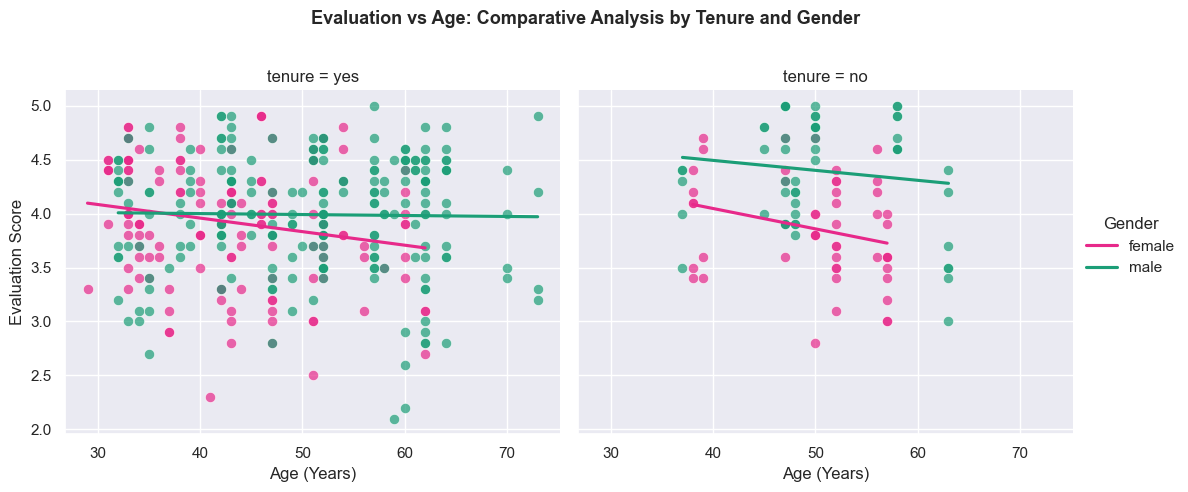

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# 1. Load dataset (defines 'df')
df = sm.datasets.get_rdataset("TeachingRatings", "AER").data
df.columns = [col.lower() for col in df.columns]

# 2. Use Faceted Layout (Subplots by Tenure) for a clean, distinct presentation
sns.set_style("darkgrid")

grid = sns.FacetGrid(
    df, 
    col="tenure", 
    hue="gender", 
    palette={"female": "#e7298a", "male": "#1b9e77"},
    height=5, 
    aspect=1.1
)

# Map scatter plot and individual regression lines
grid.map(sns.scatterplot, "age", "eval", alpha=0.7, s=55)
grid.map(sns.regplot, "age", "eval", scatter=False, ci=None)

# Formatting title and labels
grid.fig.subplots_adjust(top=0.82)
grid.fig.suptitle("Evaluation vs Age: Comparative Analysis by Tenure and Gender", fontsize=13, fontweight='bold')
grid.set_axis_labels("Age (Years)", "Evaluation Score")
grid.add_legend(title="Gender", loc="center right")

plt.show()